# Results figures

Generate figures from saved synthetic and TEP evaluation outputs. The synthetic detection metrics and model-complexity comparison share one compact 2x2 figure, and the score/alarm ablations are combined into one figure to conserve paper space. The notebook also exports an aggregate synthetic recovery summary. For a 12-page paper, prioritize the TEP comparisons.


In [1]:
from pathlib import Path
import sys


def find_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "reports").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the notebook directory.")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SYNTHETIC_RESULTS = PROJECT_ROOT / "reports" / "results" / "causalAIProcess"
TEP_RESULTS = PROJECT_ROOT / "reports" / "results" / "TEP"
SYNTHETIC_GRAPH = PROJECT_ROOT / "data" / "processed" / "causalAIProcess" / "causal_graph.csv"
SYNTHETIC_SCALED_TRACES = PROJECT_ROOT / "data" / "interim" / "causalAIProcess" / "traces_scaled.parquet"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    SYNTHETIC_RESULTS / "faulty_test_metrics.csv",
    SYNTHETIC_RESULTS / "healthy_test_metrics.csv",
    SYNTHETIC_RESULTS / "anomaly_detection_baseline_comparison.csv",
    SYNTHETIC_RESULTS / "anomaly_detection_ablation_comparison.csv",
    SYNTHETIC_RESULTS / "alarm_ablation_comparison.csv",
    SYNTHETIC_RESULTS / "detection_recovery_results.csv",
    SYNTHETIC_RESULTS / "detection_recovery_scores.parquet",
    SYNTHETIC_RESULTS / "detection_recovery_controls.parquet",
    SYNTHETIC_SCALED_TRACES,
    TEP_RESULTS / "detection_recovery_results_all.csv",
    SYNTHETIC_GRAPH,
]
missing_files = [path for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Run the synthetic detection/recovery and comparison notebooks first, and restore the "
        "complete TEP per-run summary. Missing files: "
        + ", ".join(str(path) for path in missing_files)
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Figures will be written to: {FIGURE_DIR}")


Project root: <repo>
Figures will be written to: <repo>\reports\figures


In [2]:
graph_metrics = pd.read_csv(SYNTHETIC_RESULTS / "faulty_test_metrics.csv").iloc[0]
healthy_metrics = pd.read_csv(SYNTHETIC_RESULTS / "healthy_test_metrics.csv").iloc[0]
baseline_comparison = pd.read_csv(
    SYNTHETIC_RESULTS / "anomaly_detection_baseline_comparison.csv"
)
score_ablations = pd.read_csv(
    SYNTHETIC_RESULTS / "anomaly_detection_ablation_comparison.csv"
)
alarm_ablations = pd.read_csv(SYNTHETIC_RESULTS / "alarm_ablation_comparison.csv")
recovery_results = pd.read_csv(SYNTHETIC_RESULTS / "detection_recovery_results.csv")
recovery_scores = pd.read_parquet(SYNTHETIC_RESULTS / "detection_recovery_scores.parquet")
recovery_controls = pd.read_parquet(SYNTHETIC_RESULTS / "detection_recovery_controls.parquet")
tep_results = pd.read_csv(TEP_RESULTS / "detection_recovery_results_all.csv")
causal_graph = pd.read_csv(SYNTHETIC_GRAPH)

graph_detection_rate = graph_metrics["Detected Runs"] / graph_metrics["Total Faulty Runs"]
methods = baseline_comparison.copy()
methods["Method"] = methods["Baseline"].map(
    {"full_var": "Full VAR", "pca": "PCA-SPE", "self_history": "Self-history"}
)
graph_method = pd.DataFrame(
    [{
        "Method": "Graph-informed",
        "Faulty Test Sample F1": graph_metrics["Sample F1"],
        "Faulty Test Trajectory-Phase F1": graph_metrics["Trajectory-Phase F1"],
        "Faulty Test Trajectory-Phase TPR": graph_metrics["Trajectory-Phase TPR"],
        "Faulty Test Median Detection Delay": graph_metrics["Median Detection Delay (seconds)"],
        "Healthy Test Trajectory-Phase FPR": healthy_metrics["Trajectory-Phase FPR"],
        "run_detection_rate": graph_detection_rate,
    }]
)
methods["run_detection_rate"] = methods["Faulty Test Trajectory-Phase TPR"]
methods = pd.concat([graph_method, methods], ignore_index=True)
method_order = ["Graph-informed", "Full VAR", "PCA-SPE", "Self-history"]
methods["Method"] = pd.Categorical(methods["Method"], method_order, ordered=True)
methods = methods.sort_values("Method").reset_index(drop=True)

print("Synthetic methods included:", ", ".join(methods["Method"].astype(str)))
print(f"Graph-model detection: {int(graph_metrics['Detected Runs'])}/{int(graph_metrics['Total Faulty Runs'])} faulty runs")
print(f"Healthy test runs with false alarms: {int(healthy_metrics['False Alarm Runs'])}/{int(healthy_metrics['Healthy Test Runs'])}")
print(f"TEP summary trajectories: {len(tep_results)}")


Synthetic methods included: Graph-informed, Full VAR, PCA-SPE, Self-history
Graph-model detection: 188/225 faulty runs
Healthy test runs with false alarms: 0/75
TEP summary trajectories: 10000


In [3]:
def save_figure(fig, stem):
    png_path = FIGURE_DIR / f"{stem}.png"
    pdf_path = FIGURE_DIR / f"{stem}.pdf"
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved {png_path.name} and {pdf_path.name}")


COLORS = {
    "Graph-informed": "#2A6FBB",
    "Full VAR": "#E07A2D",
    "PCA-SPE": "#777777",
    "Self-history": "#4E9A68",
}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


Saved synthetic_main_detection.png and synthetic_main_detection.pdf


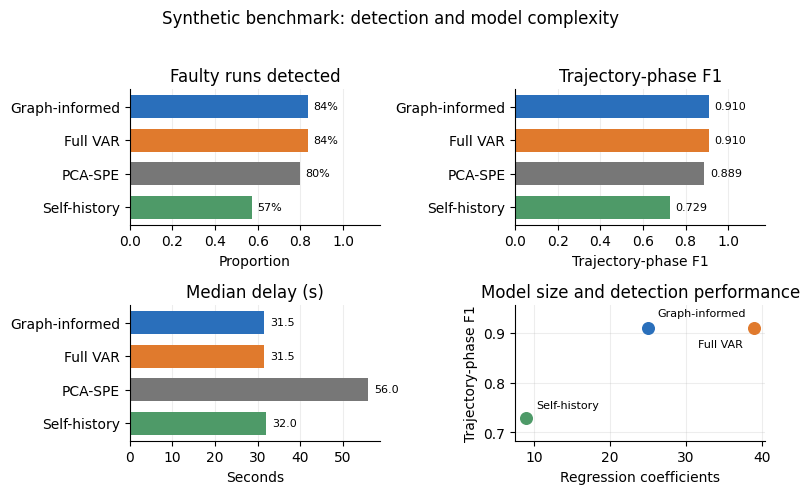

In [4]:
# Synthetic detection and model-complexity summary.
fig, axes = plt.subplots(2, 2, figsize=(7.9, 4.8))
axes = axes.ravel()
panels = [
    ("run_detection_rate", "Faulty runs detected", 1.0, "{:.0%}"),
    ("Faulty Test Trajectory-Phase F1", "Trajectory-phase F1", 1.0, "{:.3f}"),
    ("Faulty Test Median Detection Delay", "Median delay (s)", None, "{:.1f}"),
]
for ax, (column, title, xmax, label_format) in zip(axes[:3], panels, strict=True):
    values = methods[column].astype(float).to_numpy()
    y = np.arange(len(methods))
    ax.barh(y, values, color=[COLORS[str(name)] for name in methods["Method"]], height=0.68)
    ax.set_yticks(y, methods["Method"].astype(str))
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.22)
    ax.set_axisbelow(True)
    if xmax is not None:
        ax.set_xlim(0, xmax * 1.16 + 0.015)
    for yi, value in zip(y, values, strict=True):
        offset = (xmax * 0.025 if xmax is not None else max(values) * 0.025)
        ax.text(value + offset, yi, label_format.format(value), va="center", fontsize=8)
axes[0].set_xlabel("Proportion")
axes[1].set_xlabel("Trajectory-phase F1")
axes[2].set_xlabel("Seconds")
endogenous = ["reactor_concentration", "reactor_temperature", "product_quality"]
graph_parameter_count = 0
for child in endogenous:
    parents = set(causal_graph.loc[causal_graph["target"].eq(child), "source"])
    predictors = parents | {child}
    graph_parameter_count += 1 + 2 * len(predictors)
parameter_counts = {
    "Graph-informed": graph_parameter_count,
    "Full VAR": len(endogenous) * (1 + 2 * 6),
    "Self-history": len(endogenous) * (1 + 2),
}
complexity_ax = axes[3]
annotation_offsets = {"Graph-informed": (7, 8), "Full VAR": (-8, -14), "Self-history": (7, 7)}
for _, row in methods.loc[methods["Method"].astype(str).isin(parameter_counts)].iterrows():
    name = str(row["Method"])
    x = parameter_counts[name]
    y = float(row["Faulty Test Trajectory-Phase F1"])
    complexity_ax.scatter(x, y, s=70, color=COLORS[name], zorder=3)
    complexity_ax.annotate(name, (x, y), xytext=annotation_offsets[name], textcoords="offset points", fontsize=8, ha="right" if name == "Full VAR" else "left")
complexity_ax.set_xlabel("Regression coefficients")
complexity_ax.set_ylabel("Trajectory-phase F1")
complexity_ax.set_title("Model size and detection performance")
f1_values = methods.loc[methods["Method"].astype(str).isin(parameter_counts), "Faulty Test Trajectory-Phase F1"].astype(float)
f1_margin = max((f1_values.max() - f1_values.min()) * 0.25, 0.01)
complexity_ax.set_ylim(f1_values.min() - f1_margin, f1_values.max() + f1_margin)
complexity_ax.grid(alpha=0.22)
fig.suptitle("Synthetic benchmark: detection and model complexity", y=1.02, fontsize=12)
fig.tight_layout()
save_figure(fig, "synthetic_main_detection")
plt.show()


In [5]:
# Model-complexity comparison is included in synthetic_main_detection.


Saved synthetic_ablation_summary.png and synthetic_ablation_summary.pdf


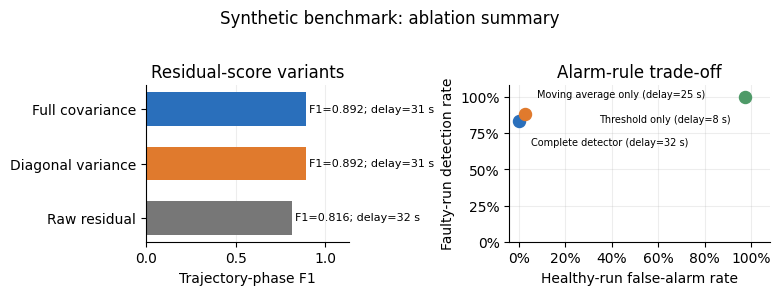

In [6]:
# Synthetic ablation summary: residual-score variants and alarm-rule trade-off.
score_labels = {
    "full_var": "Full covariance",
    "diagonal_covariance": "Diagonal variance",
    "plain_residuals": "Raw residual",
}
score = score_ablations.loc[score_ablations["Ablation"].isin(score_labels)].copy()
score["Label"] = score["Ablation"].map(score_labels)
score_order = ["Full covariance", "Diagonal variance", "Raw residual"]
score["Label"] = pd.Categorical(score["Label"], score_order, ordered=True)
score = score.sort_values("Label").reset_index(drop=True)

full_var = baseline_comparison.loc[baseline_comparison["Baseline"].eq("full_var")].iloc[0]
complete_alarm = pd.DataFrame([{
    "Alarm rule": "Complete detector",
    "detection_rate": full_var["Faulty Test Trajectory-Phase TPR"],
    "false_alarm_rate": full_var["Healthy Test Trajectory-Phase FPR"],
    "delay": full_var["Faulty Test Median Detection Delay"],
}])
ablated_alarm = alarm_ablations.rename(columns={
    "Alarm Ablation": "Alarm rule",
    "Faulty Test Trajectory-Phase TPR": "detection_rate",
    "Healthy Test Trajectory-Phase FPR": "false_alarm_rate",
    "Faulty Test Median Detection Delay": "delay",
})[["Alarm rule", "detection_rate", "false_alarm_rate", "delay"]]
alarm_plot = pd.concat([complete_alarm, ablated_alarm], ignore_index=True)
alarm_plot["Alarm rule"] = alarm_plot["Alarm rule"].replace({
    "threshold_only": "Threshold only",
    "moving_average_only": "Moving average only",
})

fig, axes = plt.subplots(1, 2, figsize=(7.9, 2.85), gridspec_kw={"width_ratios": [1.05, 1.35]})
y = np.arange(len(score))
score_values = score["Faulty Test Trajectory-Phase F1"].astype(float).to_numpy()
axes[0].barh(y, score_values, color=["#2A6FBB", "#E07A2D", "#777777"], height=0.62)
axes[0].set_yticks(y, score["Label"].astype(str))
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.13)
axes[0].set_xlabel("Trajectory-phase F1")
axes[0].set_title("Residual-score variants")
axes[0].grid(axis="x", alpha=0.22)
axes[0].set_axisbelow(True)
for yi, row in score.iterrows():
    axes[0].text(
        float(row["Faulty Test Trajectory-Phase F1"]) + 0.015,
        yi,
        f"F1={row['Faulty Test Trajectory-Phase F1']:.3f}; delay={row['Faulty Test Median Detection Delay']:.0f} s",
        va="center",
        fontsize=8,
    )

alarm_colors = {"Complete detector": "#2A6FBB", "Moving average only": "#E07A2D", "Threshold only": "#4E9A68"}
alarm_offsets = {"Complete detector": (9, -18), "Moving average only": (9, 12), "Threshold only": (-105, -18)}
for _, row in alarm_plot.iterrows():
    axes[1].scatter(row["false_alarm_rate"], row["detection_rate"], s=75, color=alarm_colors[row["Alarm rule"]], zorder=3)
    axes[1].annotate(
        f"{row['Alarm rule']} (delay={row['delay']:.0f} s)",
        (row["false_alarm_rate"], row["detection_rate"]),
        xytext=alarm_offsets[row["Alarm rule"]],
        textcoords="offset points",
        fontsize=7,
    )
axes[1].set_xlim(-0.04, 1.08)
axes[1].set_ylim(0, 1.08)
axes[1].set_xlabel("Healthy-run false-alarm rate")
axes[1].set_ylabel("Faulty-run detection rate")
axes[1].set_title("Alarm-rule trade-off")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
axes[1].grid(alpha=0.22)
axes[1].set_axisbelow(True)
fig.suptitle("Synthetic benchmark: ablation summary", y=1.02, fontsize=12)
fig.tight_layout()
save_figure(fig, "synthetic_ablation_summary")
plt.show()


Saved synthetic_recovery_example.png and synthetic_recovery_example.pdf
Illustrative run run_reaction_coupling_shift_01579: onset=200, detection=231, intervention=232, completion=246; selected near median delay and recovery time.


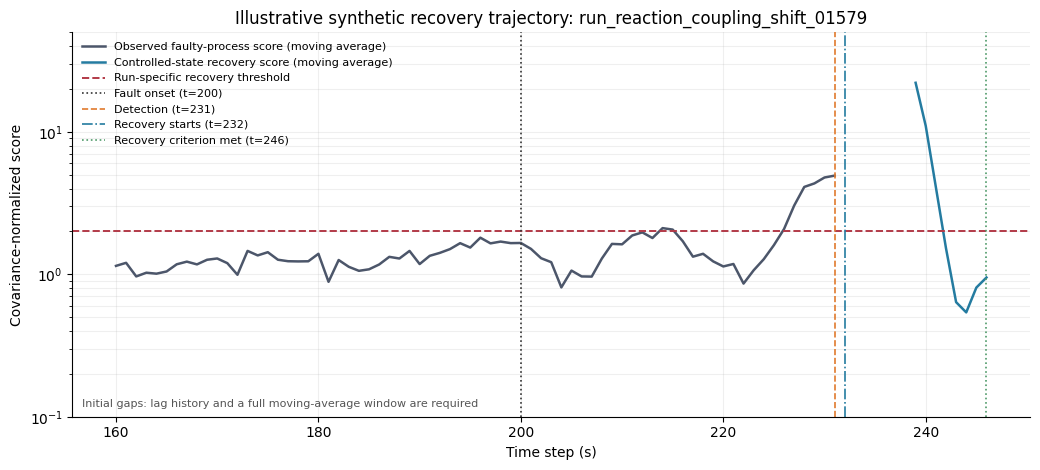

In [7]:
# Figure 5: representative recovery trace, chosen near median delay and recovery time.
recovered_runs = recovery_results.loc[
    recovery_results["fault_detected"].astype(bool)
    & recovery_results["process_recovered"].astype(bool)
].copy()
if recovered_runs.empty:
    raise ValueError("No detected and recovered synthetic run is available to illustrate.")
median_steps = recovered_runs["recovery_steps"].median()
median_delay = recovered_runs["detection_delay_samples"].median()
recovered_runs["median_distance"] = (
    (recovered_runs["recovery_steps"] - median_steps).abs()
    + (recovered_runs["detection_delay_samples"] - median_delay).abs()
)
example = recovered_runs.sort_values(["median_distance", "run_id"]).iloc[0]
run_id = example["run_id"]
run_scores = recovery_scores.loc[recovery_scores["run_id"].eq(run_id)].sort_values("time_step")
onset = int(example["fault_start_step"])
detection = int(example["detection_step"])
intervention = int(example["intervention_step"])
completion = intervention + int(example["recovery_steps"]) - 1
left = max(0, onset - 40)
right = min(int(run_scores["time_step"].max()), completion + 30)
view = run_scores.loc[run_scores["time_step"].between(left, right)]
observed_score = view["observed_process_moving_score"].where(
    view["time_step"] <= detection
)

fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.plot(
    view["time_step"],
    observed_score,
    color="#4C566A",
    linewidth=1.8,
    label="Observed faulty-process score (moving average)",
)
ax.plot(
    view["time_step"],
    view["recovery_moving_score"],
    color="#247BA0",
    linewidth=1.8,
    label="Controlled-state recovery score (moving average)",
)
ax.axhline(
    float(example["recovery_threshold"]),
    color="#B23A48",
    linestyle="--",
    linewidth=1.4,
    label="Run-specific recovery threshold",
)
markers = [
    (onset, "Fault onset", "#333333", ":"),
    (detection, "Detection", "#E07A2D", "--"),
    (intervention, "Recovery starts", "#247BA0", "-."),
    (completion, "Recovery criterion met", "#4E9A68", ":"),
]
for x, label, color, linestyle in markers:
    ax.axvline(x, color=color, linestyle=linestyle, linewidth=1.2, label=f"{label} (t={x})")
ax.set_yscale("log")
ax.set_ylim(0.1, 50)
ax.set_xlabel("Time step (s)")
ax.set_ylabel("Covariance-normalized score")
ax.set_title(f"Illustrative synthetic recovery trajectory: {run_id}")
ax.text(
    0.01,
    0.02,
    "Initial gaps: lag history and a full moving-average window are required",
    transform=ax.transAxes,
    fontsize=8,
    color="#555555",
    va="bottom",
)
ax.grid(alpha=0.2, which="both")
ax.legend(loc="best", fontsize=8, frameon=False)
fig.tight_layout()
save_figure(fig, "synthetic_recovery_example")
print(
    f"Illustrative run {run_id}: onset={onset}, detection={detection}, "
    f"intervention={intervention}, completion={completion}; selected near median delay "
    "and recovery time."
)
plt.show()


In [8]:
# Aggregate recovery outcomes across all detected synthetic test trajectories.
manipulated = ["feed_flow", "feed_concentration", "coolant_flow"]
detected_results = recovery_results.loc[
    recovery_results["fault_detected"].astype(bool)
    & recovery_results["intervention_step"].notna()
].copy()
if detected_results.empty:
    raise ValueError("No detected trajectories are eligible for recovery evaluation.")

successful_recoveries = detected_results.loc[
    detected_results["process_recovered"].astype(bool)
].copy()
if successful_recoveries.empty:
    raise ValueError("No successful recovery traces are available to summarize.")

scaled_inputs = pd.read_parquet(
    SYNTHETIC_SCALED_TRACES,
    columns=["run_id", "time_step", *manipulated],
)
run_lengths = (
    scaled_inputs.groupby("run_id")["time_step"].max().add(1).rename("trajectory_length")
)
detected_results = detected_results.join(run_lengths, on="run_id")
recovery_eligible = detected_results.loc[
    detected_results["trajectory_length"].notna()
    & detected_results["intervention_step"].lt(detected_results["trajectory_length"])
].copy()
successful_recoveries = recovery_eligible.loc[
    recovery_eligible["process_recovered"].astype(bool)
].copy()
if recovery_eligible.empty:
    raise ValueError("No detected trajectories have time remaining for an intervention.")
if successful_recoveries.empty:
    raise ValueError("No successful recovery traces are available to summarize.")

scaled_inputs = scaled_inputs.loc[
    scaled_inputs["run_id"].isin(successful_recoveries["run_id"])
]
control_efforts = []
for result in successful_recoveries.itertuples(index=False):
    actions = recovery_controls.loc[recovery_controls["run_id"].eq(result.run_id)].sort_values("time_step")
    previous = scaled_inputs.loc[
        scaled_inputs["run_id"].eq(result.run_id)
        & scaled_inputs["time_step"].eq(int(result.intervention_step) - 1),
        manipulated,
    ]
    if len(previous) != 1 or actions.empty:
        raise ValueError(f"Missing control history for recovered run {result.run_id}.")
    action_values = actions[manipulated].to_numpy(dtype=float)
    if len(action_values) != int(result.recovery_steps):
        raise ValueError(f"Control horizon does not match recovery time for {result.run_id}.")
    control_sequence = np.vstack([previous.to_numpy(dtype=float)[0], action_values])
    deltas = np.diff(control_sequence, axis=0)
    control_efforts.append(float(np.square(deltas).sum()))

recovery_summary = pd.DataFrame([{
    "Eligible detected trajectories": len(recovery_eligible),
    "Successful recoveries": len(successful_recoveries),
    "Recovery success rate": successful_recoveries.shape[0] / len(recovery_eligible),
    "Median recovery time (s; 1 s/sample)": successful_recoveries["recovery_steps"].median(),
    "Median control effort (standardized input units squared)": float(np.median(control_efforts)),
}])
summary_path = SYNTHETIC_RESULTS / "detection_recovery_aggregate_summary.csv"
recovery_summary.to_csv(summary_path, index=False)
print(f"Saved aggregate recovery summary to {summary_path}")
display(recovery_summary)


Saved aggregate recovery summary to <repo>\reports\results\causalAIProcess\detection_recovery_aggregate_summary.csv


,Eligible detected trajectories,Successful recoveries,Recovery success rate,Median recovery time (s; 1 s/sample),Median control effort (standardized input units squared)
0,188,188,1.0,15.0,3.468169


Saved tep_detection_recovery_summary.png and tep_detection_recovery_summary.pdf
Not detected               1546
Detected, not recovered      46
Detected and recovered     8408
TEP median detection delay: 19.0 samples (57.0 min)
TEP median recovery time among recovered runs: 255.0 samples (12.75 h)


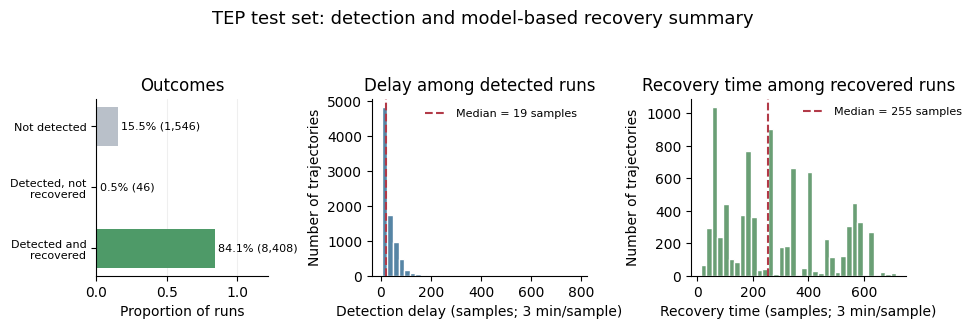

In [9]:
# Figure 6: aggregate TEP detection and recovery outcomes from the retained summary.
detected = tep_results["Anomaly Detected"].astype(bool)
recovered = tep_results["Process Recovered"].astype(bool)
outcome_counts = pd.Series(
    {
        "Not detected": int((~detected).sum()),
        "Detected, not recovered": int((detected & ~recovered).sum()),
        "Detected and recovered": int((detected & recovered).sum()),
    }
)
outcome_colors = ["#B9C0C9", "#D9826B", "#4E9A68"]
outcome_labels = ["Not detected", "Detected, not\nrecovered", "Detected and\nrecovered"]
outcome_proportions = outcome_counts.to_numpy(dtype=float) / len(tep_results)
fig, axes = plt.subplots(1, 3, figsize=(9.75, 3.15), gridspec_kw={"width_ratios": [1.0, 1.25, 1.25]})

positions = np.arange(len(outcome_counts))
axes[0].barh(positions, outcome_proportions, color=outcome_colors, height=0.64)
axes[0].set_yticks(positions, outcome_labels, fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.22)
axes[0].set_xlabel("Proportion of runs")
axes[0].set_title("Outcomes")
for y, proportion, count in zip(positions, outcome_proportions, outcome_counts.values, strict=True):
    axes[0].text(proportion + 0.025, y, f"{proportion:.1%} ({count:,})", va="center", fontsize=8)
axes[0].grid(axis="x", alpha=0.2)
axes[0].set_axisbelow(True)

delay_values = tep_results.loc[detected, "Delay"].dropna()
axes[1].hist(delay_values, bins=35, color="#5685A5", edgecolor="white")
axes[1].axvline(delay_values.median(), color="#B23A48", linestyle="--", label=f"Median = {delay_values.median():.0f} samples")
axes[1].set_xlabel("Detection delay (samples; 3 min/sample)")
axes[1].set_ylabel("Number of trajectories")
axes[1].set_title("Delay among detected runs")
axes[1].legend(fontsize=8, frameon=False)

recovery_values = tep_results.loc[detected & recovered, "Recovery Steps"].dropna()
axes[2].hist(recovery_values, bins=35, color="#6A9F75", edgecolor="white")
axes[2].axvline(recovery_values.median(), color="#B23A48", linestyle="--", label=f"Median = {recovery_values.median():.0f} samples")
axes[2].set_xlabel("Recovery time (samples; 3 min/sample)")
axes[2].set_ylabel("Number of trajectories")
axes[2].set_title("Recovery time among recovered runs")
axes[2].legend(loc="upper left", bbox_to_anchor=(0.5, 0.98), fontsize=8, frameon=False, borderaxespad=0)

fig.suptitle("TEP test set: detection and model-based recovery summary", y=1.03, fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_figure(fig, "tep_detection_recovery_summary")
print(outcome_counts.to_string())
print(f"TEP median detection delay: {delay_values.median():.1f} samples ({delay_values.median() * 3:.1f} min)")
print(f"TEP median recovery time among recovered runs: {recovery_values.median():.1f} samples ({recovery_values.median() * 3 / 60:.2f} h)")
plt.show()
